ZEROQ AI - NOTEBOOK 08: MODEL DATASET PREPARATION
Project folder: d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training
Feature dataset folder: d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\feature_engineered_data
Model-ready output folder: d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_ready_data

Dataset loaded successfully.
Dataset shape: (24000, 69)

Observation end date: 2027-02-13 00:00:00
Observation date source: Maximum complaint date used as a proxy

Duplicate batch IDs: 0

Rows before validation: 24000
Rows after basic validation: 24000

Rows excluded due to incomplete observation window: 165
Rows after observation-window filtering: 23835

Target distribution:


,Target,Batch_Count,Percentage
0,0,18798,78.87
1,1,5037,21.13


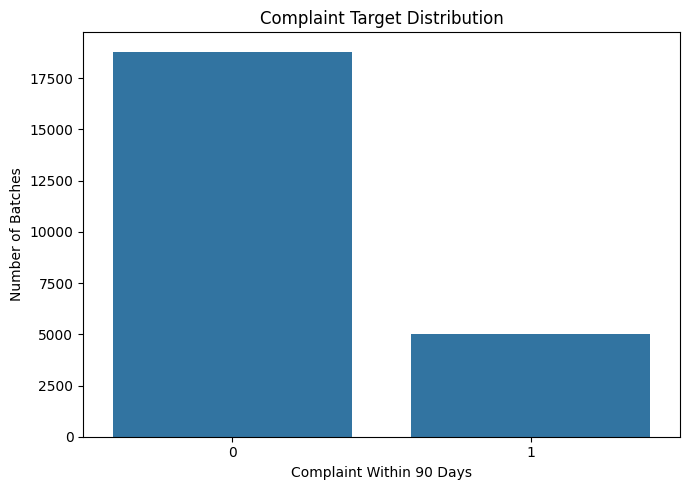


Chronological split summary:


,Dataset,Start_Year,End_Year,Rows,Positive_Batches,Positive_Percentage
0,Training,2008,2021,17776,3745,21.067732
1,Validation,2022,2023,2488,541,21.744373
2,Testing,2024,2026,3571,751,21.030524



Excluded columns:
['batch_id', 'complaint_within_90_days', 'facility_id', 'machine_id', 'packaging_material_id', 'prediction_date', 'prediction_date_source', 'prediction_year', 'product_id', 'production_line_id', 'raw_material_id', 'target_complaint_count']

Number of selected features: 54

Numerical feature count: 37
Categorical feature count: 17

Numerical features:
['units_produced', 'process_temperature_c', 'ambient_humidity_pct', 'line_pressure_bar', 'sealing_temperature_c', 'days_since_last_maintenance', 'process_deviation_flag', 'prediction_month', 'prediction_quarter', 'prediction_day_of_week', 'prediction_day', 'prediction_week_of_year', 'is_weekend', 'month_sin', 'month_cos', 'product_shelf_life_days', 'line_commissioned_year', 'packaging_shelf_life_days', 'raw_material_shelf_life_days', 'product_complaints_prior_all_time_count', 'product_complaints_prior_365d_count', 'facility_complaints_prior_all_time_count', 'facility_complaints_prior_365d_count', 'line_complaints_prior_a

,Feature_Index,Feature_Name
0,0,numeric__units_produced
1,1,numeric__process_temperature_c
2,2,numeric__ambient_humidity_pct
3,3,numeric__line_pressure_bar
4,4,numeric__sealing_temperature_c
5,5,numeric__days_since_last_maintenance
6,6,numeric__process_deviation_flag
7,7,numeric__prediction_month
8,8,numeric__prediction_quarter
9,9,numeric__prediction_day_of_week



Sparse feature matrices saved.
Target arrays saved.
Preprocessing pipeline saved.


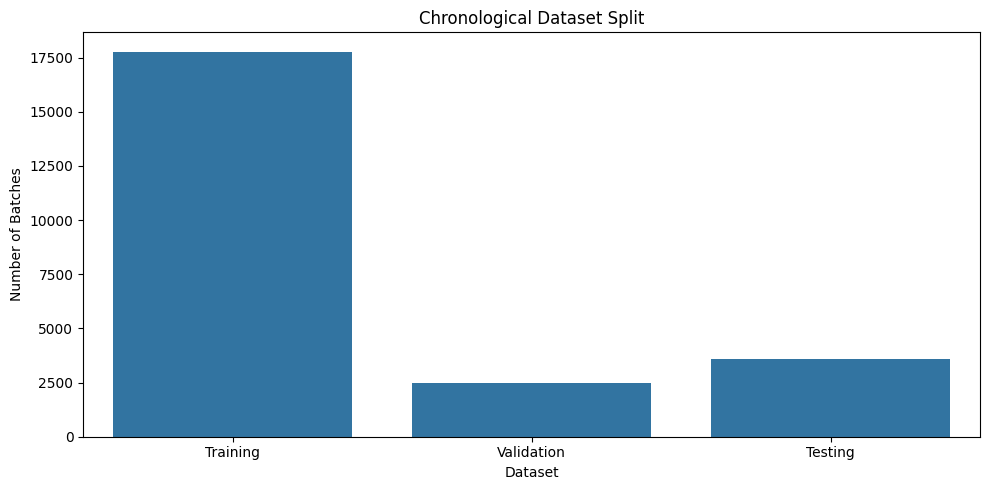

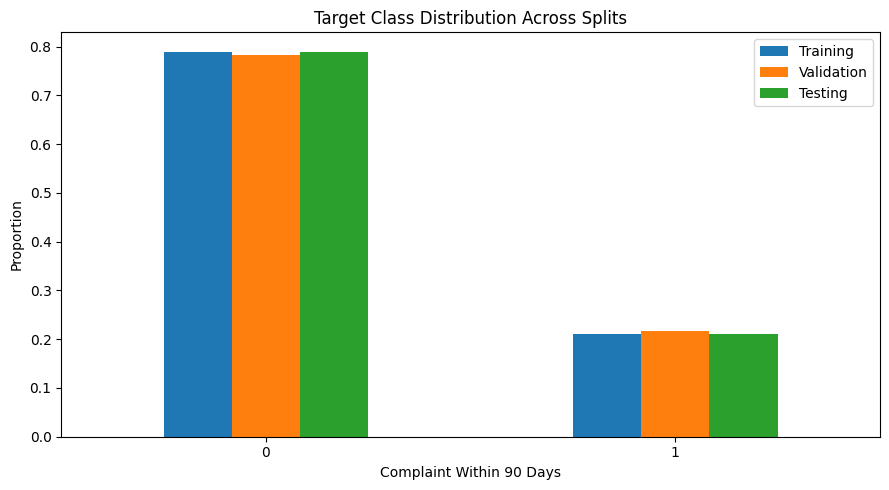


Preparation report saved.

All dataset validation checks passed.

MODEL DATASET PREPARATION COMPLETED

TRAINING DATA
Rows: 17776
Features: 10038

VALIDATION DATA
Rows: 2488
Features: 10038

TEST DATA
Rows: 3571
Features: 10038

OUTPUT FILES:
1. X_train.npz
2. X_validation.npz
3. X_test.npz
4. y_train.npy
5. y_validation.npy
6. y_test.npy
7. preprocessor.joblib
8. feature_metadata.csv
9. transformed_feature_names.csv
10. train_raw.csv
11. validation_raw.csv
12. test_raw.csv
13. train_mapping.csv
14. validation_mapping.csv
15. test_mapping.csv

OUTPUT FOLDER:
d:\AI WORKSHOP\Hackathon\Sakthi Hackathon - ML Training\model_ready_data

IMPORTANT:
- Training data is used to fit the preprocessing pipeline.
- Validation and test data are transformed without refitting.
- The chronological split is not randomly shuffled.
- Batch IDs and target-related fields are not model inputs.
- Use validation data for model selection and tuning.
- Use test data only for final model evaluation.
- These synthe

In [1]:

# ============================================================
# NOTEBOOK 08: MODEL DATASET PREPARATION
# Project: ZeroQ AI - Predictive Quality Intelligence System
# Objective: Prepare leakage-safe train, validation and test data
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import scipy.sparse as sp

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("=" * 80)
print("ZEROQ AI - NOTEBOOK 08: MODEL DATASET PREPARATION")
print("=" * 80)


# ============================================================
# 1. LOCATE PROJECT FOLDERS
# ============================================================

search_roots = [Path.cwd()] + list(Path.cwd().parents)

PROJECT_PATH = None

for root in search_roots:
    candidate = root / "feature_engineered_data"

    if (candidate / "batch_model_features.csv").exists():
        PROJECT_PATH = root
        break

if PROJECT_PATH is None:
    raise FileNotFoundError(
        "Could not locate feature_engineered_data/batch_model_features.csv.\n"
        f"Current working directory: {Path.cwd()}\n"
        "Run Notebook 7 successfully before running Notebook 8."
    )

FEATURE_PATH = PROJECT_PATH / "feature_engineered_data"
PROCESSED_PATH = PROJECT_PATH / "processed_data"

MODEL_READY_PATH = PROJECT_PATH / "model_ready_data"
REPORT_PATH = PROJECT_PATH / "preprocessing" / "reports"
VISUALIZATION_PATH = PROJECT_PATH / "visualizations" / "model_preparation"

MODEL_READY_PATH.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)
VISUALIZATION_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_PATH)
print("Feature dataset folder:", FEATURE_PATH)
print("Model-ready output folder:", MODEL_READY_PATH)


# ============================================================
# 2. CONFIGURATION
# ============================================================

TARGET_COLUMN = "complaint_within_90_days"

TARGET_COUNT_COLUMN = "target_complaint_count"

PREDICTION_DATE_COLUMN = "prediction_date"

BATCH_ID_COLUMN = "batch_id"

COMPLAINT_HORIZON_DAYS = 90

# Chronological split boundaries.
TRAIN_END_YEAR = 2021
VALIDATION_END_YEAR = 2023
TEST_END_YEAR = 2026

# Optional:
# Set this to the actual last date through which complaints
# were completely recorded in your source data.
#
# Example:
# OBSERVATION_END_DATE = "2027-03-31"
#
# If None, the maximum complaint_date in complaints_cleaned.csv
# is used as a proxy. This is NOT necessarily the true database
# extraction or observation end date.

OBSERVATION_END_DATE = None

# Minimum number of rows required in each split.
MIN_SPLIT_ROWS = 1


# ============================================================
# 3. LOAD FEATURE-ENGINEERED DATASET
# ============================================================

dataset_path = FEATURE_PATH / "batch_model_features.csv"

df = pd.read_csv(
    dataset_path,
    low_memory=False
)

df.columns = df.columns.str.strip()

print("\nDataset loaded successfully.")
print("Dataset shape:", df.shape)

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' is missing."
    )

if PREDICTION_DATE_COLUMN not in df.columns:
    raise ValueError(
        f"'{PREDICTION_DATE_COLUMN}' is missing."
    )

df[PREDICTION_DATE_COLUMN] = pd.to_datetime(
    df[PREDICTION_DATE_COLUMN],
    errors="coerce"
)

df[TARGET_COLUMN] = pd.to_numeric(
    df[TARGET_COLUMN],
    errors="coerce"
)

if TARGET_COUNT_COLUMN in df.columns:
    df[TARGET_COUNT_COLUMN] = pd.to_numeric(
        df[TARGET_COUNT_COLUMN],
        errors="coerce"
    )


# ============================================================
# 4. LOAD COMPLAINT DATA TO DETERMINE OBSERVATION END
# ============================================================

complaint_file = PROCESSED_PATH / "complaints_cleaned.csv"

if complaint_file.exists():

    complaint_data = pd.read_csv(
        complaint_file,
        low_memory=False
    )

    complaint_date_candidates = [
        "complaint_date",
        "date_received",
        "received_date",
        "reported_date",
        "created_at"
    ]

    complaint_date_column = None

    lower_columns = {
        col.lower(): col
        for col in complaint_data.columns
    }

    for candidate in complaint_date_candidates:
        if candidate in lower_columns:
            complaint_date_column = lower_columns[candidate]
            break

    if complaint_date_column is None:
        for col in complaint_data.columns:
            if any(
                word in col.lower()
                for word in [
                    "complaint_date",
                    "received_date",
                    "reported_date"
                ]
            ):
                complaint_date_column = col
                break

    if complaint_date_column:
        complaint_data[complaint_date_column] = pd.to_datetime(
            complaint_data[complaint_date_column],
            errors="coerce"
        )

        maximum_complaint_date = (
            complaint_data[complaint_date_column].max()
        )
    else:
        maximum_complaint_date = None

else:
    maximum_complaint_date = None


if OBSERVATION_END_DATE is not None:

    observation_end_date = pd.Timestamp(
        OBSERVATION_END_DATE
    )

    observation_date_source = "Manually configured date"

elif maximum_complaint_date is not None:

    observation_end_date = pd.Timestamp(
        maximum_complaint_date
    )

    observation_date_source = (
        "Maximum complaint date used as a proxy"
    )

else:

    observation_end_date = None

    observation_date_source = "Unavailable"


print("\nObservation end date:", observation_end_date)
print("Observation date source:", observation_date_source)


# ============================================================
# 5. BASIC DATA VALIDATION
# ============================================================

initial_rows = len(df)

# Remove rows without prediction dates.
df = df.dropna(
    subset=[PREDICTION_DATE_COLUMN]
).copy()

# Remove rows without target labels.
df = df.dropna(
    subset=[TARGET_COLUMN]
).copy()

# Ensure binary target values.
df = df[
    df[TARGET_COLUMN].isin([0, 1])
].copy()

df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)

# Remove duplicate batch IDs if available.
if BATCH_ID_COLUMN in df.columns:

    duplicate_count = df[BATCH_ID_COLUMN].duplicated().sum()

    print("\nDuplicate batch IDs:", duplicate_count)

    if duplicate_count > 0:
        df = df.drop_duplicates(
            subset=[BATCH_ID_COLUMN],
            keep="first"
        ).copy()

print("\nRows before validation:", initial_rows)
print("Rows after basic validation:", len(df))


# ============================================================
# 6. REMOVE INCOMPLETE 90-DAY OBSERVATION WINDOWS
# ============================================================

# A batch should not be labelled as a negative if the full
# 90-day complaint observation window has not elapsed.

if observation_end_date is not None:

    df["label_observation_end"] = (
        df[PREDICTION_DATE_COLUMN]
        + pd.to_timedelta(
            COMPLAINT_HORIZON_DAYS,
            unit="D"
        )
    )

    complete_window_mask = (
        df["label_observation_end"]
        <= observation_end_date
    )

    incomplete_window_count = (
        (~complete_window_mask).sum()
    )

    df = df[complete_window_mask].copy()

    print(
        "\nRows excluded due to incomplete observation window:",
        incomplete_window_count
    )

else:

    incomplete_window_count = 0

    print(
        "\nWARNING: Observation end date unavailable. "
        "Cannot verify complete 90-day follow-up windows."
    )

df = df.drop(
    columns=["label_observation_end"],
    errors="ignore"
)

print("Rows after observation-window filtering:", len(df))


# ============================================================
# 7. CHECK TARGET DISTRIBUTION
# ============================================================

target_distribution = (
    df[TARGET_COLUMN]
    .value_counts()
    .sort_index()
    .rename_axis("Target")
    .reset_index(name="Batch_Count")
)

target_distribution["Percentage"] = (
    target_distribution["Batch_Count"]
    / target_distribution["Batch_Count"].sum()
    * 100
).round(2)

print("\nTarget distribution:")
display(target_distribution)

if df[TARGET_COLUMN].nunique() < 2:
    raise ValueError(
        "Only one target class remains after filtering. "
        "Check the target construction and observation window."
    )

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET_COLUMN
)

plt.title("Complaint Target Distribution")
plt.xlabel("Complaint Within 90 Days")
plt.ylabel("Number of Batches")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. CREATE CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLITS
# ============================================================

df["prediction_year"] = (
    df[PREDICTION_DATE_COLUMN].dt.year
)

train_df = df[
    df["prediction_year"] <= TRAIN_END_YEAR
].copy()

validation_df = df[
    (
        df["prediction_year"] > TRAIN_END_YEAR
    )
    &
    (
        df["prediction_year"] <= VALIDATION_END_YEAR
    )
].copy()

test_df = df[
    (
        df["prediction_year"] > VALIDATION_END_YEAR
    )
    &
    (
        df["prediction_year"] <= TEST_END_YEAR
    )
].copy()

# Do not randomly shuffle time-based data.
# This keeps the evaluation closer to real deployment.

split_summary = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],
    "Start_Year": [
        df["prediction_year"].min(),
        TRAIN_END_YEAR + 1,
        VALIDATION_END_YEAR + 1
    ],
    "End_Year": [
        TRAIN_END_YEAR,
        VALIDATION_END_YEAR,
        TEST_END_YEAR
    ],
    "Rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Positive_Batches": [
        int(train_df[TARGET_COLUMN].sum()),
        int(validation_df[TARGET_COLUMN].sum()),
        int(test_df[TARGET_COLUMN].sum())
    ]
})

split_summary["Positive_Percentage"] = [
    (
        train_df[TARGET_COLUMN].mean() * 100
        if len(train_df) else np.nan
    ),
    (
        validation_df[TARGET_COLUMN].mean() * 100
        if len(validation_df) else np.nan
    ),
    (
        test_df[TARGET_COLUMN].mean() * 100
        if len(test_df) else np.nan
    )
]

print("\nChronological split summary:")
display(split_summary)

for name, split in {
    "Training": train_df,
    "Validation": validation_df,
    "Testing": test_df
}.items():

    if len(split) < MIN_SPLIT_ROWS:
        raise ValueError(
            f"{name} dataset has insufficient rows. "
            "Check the available date range and split boundaries."
        )

    if split[TARGET_COLUMN].nunique() < 2:
        print(
            f"WARNING: {name} split contains only one target class. "
            "Classification metrics such as ROC-AUC may not be available."
        )


# ============================================================
# 9. REMOVE IDENTIFIERS, TARGETS AND LEAKAGE-PRONE FEATURES
# ============================================================

# These are not valid model predictors.
explicit_exclusions = [
    TARGET_COLUMN,
    TARGET_COUNT_COLUMN,
    BATCH_ID_COLUMN,
    PREDICTION_DATE_COLUMN,
    "prediction_year",
    "prediction_date_source"
]

# Additional leakage-sensitive terms.
leakage_keywords = [
    "complaint_occurred",
    "complaint_count",
    "complaint_count_linked",
    "target_complaint",
    "investigation",
    "corrective_action",
    "root_cause",
    "resolution",
    "complaint_status",
    "customer_feedback"
]

excluded_columns = []

for col in df.columns:

    lower = col.lower()

    if col in explicit_exclusions:
        excluded_columns.append(col)
        continue

    if any(
        keyword in lower
        for keyword in leakage_keywords
    ):
        excluded_columns.append(col)
        continue

    if lower.endswith("_id"):
        excluded_columns.append(col)
        continue

# Identify date and datetime columns.
date_columns = []

for col in df.columns:

    if col in explicit_exclusions:
        continue

    if pd.api.types.is_datetime64_any_dtype(df[col]):
        date_columns.append(col)

# Raw date columns are excluded from the model.
excluded_columns.extend(date_columns)

excluded_columns = sorted(set(excluded_columns))

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

# Retain only columns with at least one non-null value.
feature_columns = [
    col for col in feature_columns
    if df[col].notna().any()
]

# Remove constant columns.
feature_columns = [
    col for col in feature_columns
    if df[col].nunique(dropna=True) > 1
]

if not feature_columns:
    raise ValueError(
        "No usable feature columns remain. "
        "Review the exclusion rules and feature-engineered dataset."
    )

print("\nExcluded columns:")
print(excluded_columns)

print("\nNumber of selected features:", len(feature_columns))


# ============================================================
# 10. SEPARATE NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

X_train = train_df[feature_columns].copy()
X_validation = validation_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_train = train_df[TARGET_COLUMN].copy()
y_validation = validation_df[TARGET_COLUMN].copy()
y_test = test_df[TARGET_COLUMN].copy()

# Convert numeric-looking object columns to numeric when
# conversion is reliable. This uses each column's own values
# but does not learn any imputation or scaling statistics.

for col in feature_columns:

    if X_train[col].dtype == "object":

        train_numeric = pd.to_numeric(
            X_train[col],
            errors="coerce"
        )

        # Convert only if the training data is predominantly numeric.
        non_missing = X_train[col].notna().sum()

        if non_missing > 0:
            conversion_ratio = (
                train_numeric.notna().sum()
                / non_missing
            )

            if conversion_ratio >= 0.95:

                X_train[col] = train_numeric

                X_validation[col] = pd.to_numeric(
                    X_validation[col],
                    errors="coerce"
                )

                X_test[col] = pd.to_numeric(
                    X_test[col],
                    errors="coerce"
                )

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("\nNumerical feature count:", len(numeric_features))
print("Categorical feature count:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


# ============================================================
# 11. BUILD PREPROCESSING PIPELINES
# ============================================================

# Numeric:
# - Median imputation
#
# Categorical:
# - Most frequent imputation
# - One-Hot Encoding
#
# All learned preprocessing parameters are fitted on training
# data only. Validation and test data are transformed using
# the already-fitted training pipeline.

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

transformers = []

if numeric_features:
    transformers.append(
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        )
    )

if categorical_features:
    transformers.append(
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)


# ============================================================
# 12. FIT ON TRAINING DATA ONLY
# ============================================================

print("\nFitting preprocessing pipeline on training data...")

X_train_transformed = preprocessor.fit_transform(
    X_train
)

print("Transforming validation data...")

X_validation_transformed = preprocessor.transform(
    X_validation
)

print("Transforming test data...")

X_test_transformed = preprocessor.transform(
    X_test
)

print("\nTransformation completed.")

print(
    "Training transformed shape:",
    X_train_transformed.shape
)

print(
    "Validation transformed shape:",
    X_validation_transformed.shape
)

print(
    "Testing transformed shape:",
    X_test_transformed.shape
)


# ============================================================
# 13. GENERATE TRANSFORMED FEATURE NAMES
# ============================================================

try:

    transformed_feature_names = (
        preprocessor.get_feature_names_out()
    )

except Exception:

    transformed_feature_names = np.array(
        [
            f"feature_{i}"
            for i in range(X_train_transformed.shape[1])
        ]
    )

feature_names_df = pd.DataFrame({
    "Feature_Index": range(len(transformed_feature_names)),
    "Feature_Name": transformed_feature_names
})

print("\nTransformed feature count:")
print(len(transformed_feature_names))

display(feature_names_df.head(20))


# ============================================================
# 14. SAVE TRANSFORMED DATA AS SPARSE MATRICES
# ============================================================

# Sparse storage avoids unnecessarily converting one-hot
# encoded data into large dense arrays.

def save_sparse_matrix(matrix, path):

    if sp.issparse(matrix):
        sparse_matrix = matrix.tocsr()
    else:
        sparse_matrix = sp.csr_matrix(matrix)

    sp.save_npz(path, sparse_matrix)


save_sparse_matrix(
    X_train_transformed,
    MODEL_READY_PATH / "X_train.npz"
)

save_sparse_matrix(
    X_validation_transformed,
    MODEL_READY_PATH / "X_validation.npz"
)

save_sparse_matrix(
    X_test_transformed,
    MODEL_READY_PATH / "X_test.npz"
)

print("\nSparse feature matrices saved.")


# ============================================================
# 15. SAVE TARGET ARRAYS
# ============================================================

np.save(
    MODEL_READY_PATH / "y_train.npy",
    y_train.to_numpy()
)

np.save(
    MODEL_READY_PATH / "y_validation.npy",
    y_validation.to_numpy()
)

np.save(
    MODEL_READY_PATH / "y_test.npy",
    y_test.to_numpy()
)

print("Target arrays saved.")


# ============================================================
# 16. SAVE BATCH ID AND DATE MAPPING
# ============================================================

# Keep a separate mapping so model predictions can later be
# connected to their original production batches.

def save_mapping(split_df, split_name):

    mapping_columns = [
        col for col in [
            BATCH_ID_COLUMN,
            PREDICTION_DATE_COLUMN,
            TARGET_COLUMN
        ]
        if col in split_df.columns
    ]

    mapping = split_df[mapping_columns].copy()

    mapping.to_csv(
        MODEL_READY_PATH / f"{split_name}_mapping.csv",
        index=False
    )


save_mapping(train_df, "train")
save_mapping(validation_df, "validation")
save_mapping(test_df, "test")


# ============================================================
# 17. SAVE RAW CHRONOLOGICAL SPLITS
# ============================================================

# These files preserve the selected untransformed feature values
# for inspection and debugging.

train_export = train_df[
    feature_columns + [TARGET_COLUMN]
].copy()

validation_export = validation_df[
    feature_columns + [TARGET_COLUMN]
].copy()

test_export = test_df[
    feature_columns + [TARGET_COLUMN]
].copy()

train_export.to_csv(
    MODEL_READY_PATH / "train_raw.csv",
    index=False
)

validation_export.to_csv(
    MODEL_READY_PATH / "validation_raw.csv",
    index=False
)

test_export.to_csv(
    MODEL_READY_PATH / "test_raw.csv",
    index=False
)


# ============================================================
# 18. SAVE PREPROCESSING PIPELINE
# ============================================================

joblib.dump(
    preprocessor,
    MODEL_READY_PATH / "preprocessor.joblib"
)

print("Preprocessing pipeline saved.")


# ============================================================
# 19. SAVE FEATURE METADATA
# ============================================================

feature_metadata = pd.DataFrame({
    "Feature": feature_columns,
    "Data_Type": [
        str(X_train[col].dtype)
        for col in feature_columns
    ],
    "Feature_Category": [
        (
            "Numerical"
            if col in numeric_features
            else "Categorical"
        )
        for col in feature_columns
    ],
    "Training_Missing_Percentage": [
        round(X_train[col].isna().mean() * 100, 2)
        for col in feature_columns
    ]
})

feature_metadata.to_csv(
    MODEL_READY_PATH / "feature_metadata.csv",
    index=False
)

feature_names_df.to_csv(
    MODEL_READY_PATH / "transformed_feature_names.csv",
    index=False
)


# ============================================================
# 20. VISUALIZE CHRONOLOGICAL SPLITS
# ============================================================

plt.figure(figsize=(10, 5))

split_plot = pd.DataFrame({
    "Year": [
        train_df["prediction_year"].min(),
        validation_df["prediction_year"].min(),
        test_df["prediction_year"].min()
    ],
    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],
    "Rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ]
})

sns.barplot(
    data=split_plot,
    x="Dataset",
    y="Rows"
)

plt.title("Chronological Dataset Split")
plt.xlabel("Dataset")
plt.ylabel("Number of Batches")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "chronological_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 21. TARGET DISTRIBUTION ACROSS SPLITS
# ============================================================

split_target = pd.DataFrame({
    "Training": train_df[TARGET_COLUMN].value_counts(normalize=True),
    "Validation": validation_df[TARGET_COLUMN].value_counts(normalize=True),
    "Testing": test_df[TARGET_COLUMN].value_counts(normalize=True)
}).fillna(0)

split_target.index.name = "Target"

split_target.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Target Class Distribution Across Splits")
plt.xlabel("Complaint Within 90 Days")
plt.ylabel("Proportion")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "target_distribution_by_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 22. DATASET PREPARATION REPORT
# ============================================================

split_report = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],
    "Rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Features_Before_Encoding": [
        len(feature_columns)
    ] * 3,
    "Features_After_Encoding": [
        X_train_transformed.shape[1],
        X_validation_transformed.shape[1],
        X_test_transformed.shape[1]
    ],
    "Positive_Count": [
        int(y_train.sum()),
        int(y_validation.sum()),
        int(y_test.sum())
    ],
    "Negative_Count": [
        int((y_train == 0).sum()),
        int((y_validation == 0).sum()),
        int((y_test == 0).sum())
    ]
})

preparation_summary = pd.DataFrame({
    "Metric": [
        "Initial Rows",
        "Final Rows",
        "Excluded Incomplete Observation Rows",
        "Training End Year",
        "Validation End Year",
        "Test End Year",
        "Complaint Horizon Days",
        "Observation End Date",
        "Observation Date Source",
        "Numerical Features",
        "Categorical Features",
        "Total Features Before Encoding",
        "Total Features After Encoding"
    ],
    "Value": [
        initial_rows,
        len(df),
        incomplete_window_count,
        TRAIN_END_YEAR,
        VALIDATION_END_YEAR,
        TEST_END_YEAR,
        COMPLAINT_HORIZON_DAYS,
        str(observation_end_date),
        observation_date_source,
        len(numeric_features),
        len(categorical_features),
        len(feature_columns),
        X_train_transformed.shape[1]
    ]
})

with pd.ExcelWriter(
    REPORT_PATH / "model_dataset_preparation_report.xlsx",
    engine="openpyxl"
) as writer:

    preparation_summary.to_excel(
        writer,
        sheet_name="Overview",
        index=False
    )

    split_report.to_excel(
        writer,
        sheet_name="Dataset_Splits",
        index=False
    )

    feature_metadata.to_excel(
        writer,
        sheet_name="Feature_Metadata",
        index=False
    )

    target_distribution.to_excel(
        writer,
        sheet_name="Overall_Target",
        index=False
    )

    split_target.to_excel(
        writer,
        sheet_name="Target_By_Split"
    )

    feature_names_df.to_excel(
        writer,
        sheet_name="Encoded_Features",
        index=False
    )

print("\nPreparation report saved.")


# ============================================================
# 23. FINAL VALIDATION
# ============================================================

assert X_train_transformed.shape[0] == len(y_train)
assert X_validation_transformed.shape[0] == len(y_validation)
assert X_test_transformed.shape[0] == len(y_test)

assert X_train_transformed.shape[1] == X_validation_transformed.shape[1]
assert X_train_transformed.shape[1] == X_test_transformed.shape[1]

assert set(y_train.unique()).issubset({0, 1})
assert set(y_validation.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

print("\nAll dataset validation checks passed.")


# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("MODEL DATASET PREPARATION COMPLETED")
print("=" * 80)

print("\nTRAINING DATA")
print("Rows:", X_train_transformed.shape[0])
print("Features:", X_train_transformed.shape[1])

print("\nVALIDATION DATA")
print("Rows:", X_validation_transformed.shape[0])
print("Features:", X_validation_transformed.shape[1])

print("\nTEST DATA")
print("Rows:", X_test_transformed.shape[0])
print("Features:", X_test_transformed.shape[1])

print("\nOUTPUT FILES:")
print("1. X_train.npz")
print("2. X_validation.npz")
print("3. X_test.npz")
print("4. y_train.npy")
print("5. y_validation.npy")
print("6. y_test.npy")
print("7. preprocessor.joblib")
print("8. feature_metadata.csv")
print("9. transformed_feature_names.csv")
print("10. train_raw.csv")
print("11. validation_raw.csv")
print("12. test_raw.csv")
print("13. train_mapping.csv")
print("14. validation_mapping.csv")
print("15. test_mapping.csv")

print("\nOUTPUT FOLDER:")
print(MODEL_READY_PATH)

print("\nIMPORTANT:")
print("- Training data is used to fit the preprocessing pipeline.")
print("- Validation and test data are transformed without refitting.")
print("- The chronological split is not randomly shuffled.")
print("- Batch IDs and target-related fields are not model inputs.")
print("- Use validation data for model selection and tuning.")
print("- Use test data only for final model evaluation.")
print("- These synthetic data results do not establish real-world accuracy.")

print("\nNOTEBOOK 08 COMPLETED SUCCESSFULLY.")
